In [29]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz

In [30]:
df = pd.read_csv("pose_sleep_data_world.csv")

In [31]:
# dropping invalid rows
df = df[df["sleep"] != -1]

In [32]:
X = df.iloc[:, :-1].values  # All landmark coordinates
y = df.iloc[:, -1].values   # Labels (0 = Awake, 1 = Sleeping)

In [33]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 640, Testing samples: 160


In [34]:
### TRAINING

In [37]:
## FOR HYPER TUNING THE PARAMS
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {'n_estimators': randint(50,500),
              'max_depth': randint(1,20),
              'random_state': randint(1,100)
              }

rf = RandomForestClassifier()

rand_search = RandomizedSearchCV(rf, 
                                 param_distributions = param_dist, 
                                 n_iter=5, 
                                 cv=5)

rand_search.fit(X_train, y_train)

best_rf = rand_search.best_estimator_

# Print the best hyperparameters
print('Best hyperparameters:',  rand_search.best_params_)

Best hyperparameters: {'max_depth': 6, 'n_estimators': 421, 'random_state': 61}


In [38]:
model = RandomForestClassifier(n_estimators=284, random_state=61, max_depth=6)
model.fit(X_train, y_train)

# Predict on test set
y_pred = model.predict(X_test)

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2f}")

Model Accuracy: 0.97


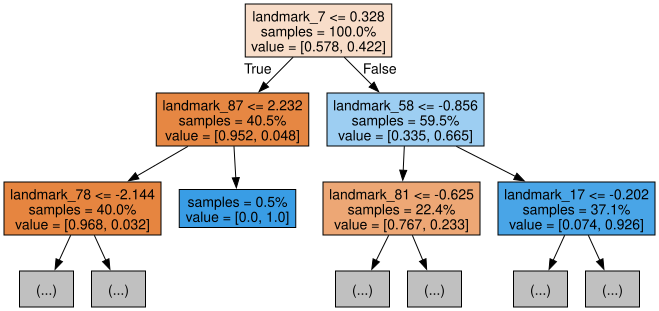

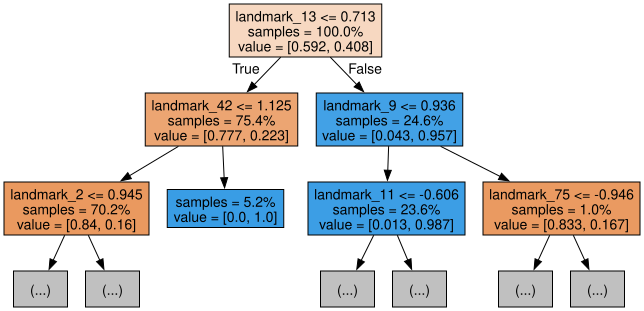

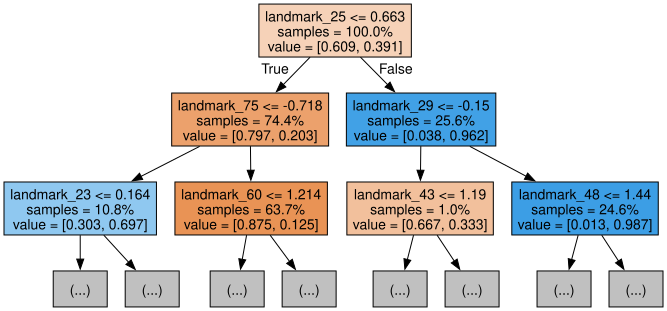

In [27]:
#### Displauy tree

for i in range(3):
    tree = model.estimators_[i]
    dot_data = export_graphviz(tree,
                               feature_names=[f"landmark_{i}" for i in range(X_train.shape[1])],  
                               filled=True,  
                               max_depth=2, 
                               impurity=False, 
                               proportion=True)
    graph = graphviz.Source(dot_data)
    display(graph)
    